# Preference-Based Music Playlist Generation Under Duration and Genre Diversity Constraints

Binary Integer Linear Programming (BILP) model solved with **PuLP + CBC** (Branch and Cut) for every user and every experimental configuration.

**Pipeline**

1. `load_users` – load and validate one CSV per user.
2. `build_model` – build the BILP model for one user and one configuration.
3. `solve_model` – solve with CBC (with a time limit) and extract the playlist.
4. `run_experiments` – run every user × duration window × genre requirement.
5. `compare` – statistics, comparison tables and figures.

**Model**

$$\max Z = \sum_{i \in I} p_i x_i$$

subject to

$$\sum_{i} d_i x_i \ge D_{\min}, \qquad \sum_{i} d_i x_i \le D_{\max}, \qquad \sum_{g} z_g \ge G_{\min}$$
$$z_g \le \sum_{i} a_{ig} x_i \quad \forall g \in G, \qquad x_i \le z_g \quad \forall i, g : a_{ig} = 1$$
$$x_i \in \{0,1\}, \quad z_g \in \{0,1\}$$

The objective is the **sum** of the preference scores of the selected songs. The average preference per selected song is reported as an extra metric only; it does not replace the objective.

**Outputs** (all in `results/`):

- `experiment_summary.csv`, `playlist_details.csv`, `load_report.csv`
- `config_statistics.csv`, `status_summary.csv`, `comparison_*.csv`, `unsuccessful_experiments.csv`
- `figures/*.png`

## 1. Imports and configuration

In [43]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pulp

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("PuLP version:", pulp.__version__)

PuLP version: 4.2.0


In [ ]:
# ----------------------------- CONFIGURATION -----------------------------
# Folder with one CSV per user. Required columns: song_id, duration (seconds),
# preference_score and one or more binary genre_* columns.
DATA_DIR = Path("../data/processed/users")

N_USERS = 20                   # None = all users; an int = first n files (sorted by name)

RESULTS_DIR = Path("./results")
FIGURES_DIR = RESULTS_DIR / "figures"

# Valid range for preference_score (None = no bound on that side).
PREFERENCE_RANGE = (0.0, None)

# CBC settings
TIME_LIMIT = 60                  # seconds per model
SOLVER_MSG = False               # True prints the CBC log

# Experimental configurations: every duration window is combined with every genre
# requirement (independently for every user).
DURATION_CONFIGS = [(1200, 1800), (1800, 2400), (2400, 3000)]
GENRE_CONFIGS = [3, 5]


RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Data directory   :", DATA_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())

Data directory   : C:\Users\Ale\Downloads\Optimization methods\Proyecto_2\data\processed\users
Results directory: C:\Users\Ale\Downloads\Optimization methods\Proyecto_2\music-playlist-ilp\results


## 2. `load_users` – load and validate user data

In [46]:
REQUIRED_COLUMNS = ["song_id", "duration", "preference_score"]
GENRE_PREFIX = "genre_"


def get_genre_columns(df):
    """Genre columns are identified dynamically by the 'genre_' prefix."""
    return [c for c in df.columns if c.startswith(GENRE_PREFIX)]


def extract_user_id(csv_path):
    """'user_123.csv' -> '123'; any other filename -> its stem."""
    stem = Path(csv_path).stem
    m = re.match(r"^user[_-]?(.+)$", stem, flags=re.IGNORECASE)
    return m.group(1) if m else stem


def validate_user_df(df, preference_range=PREFERENCE_RANGE):
    """Return (clean_df, errors, warnings_list) for one user's DataFrame."""
    errors, warns = [], []

    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    genre_cols = get_genre_columns(df)
    if missing:
        errors.append(f"missing required columns: {missing}")
    if not genre_cols:
        errors.append("no genre_* columns found")
    if errors:
        return df, errors, warns

    df = df.copy()
    df["song_id"] = df["song_id"].astype(str).str.strip()

    # Missing values
    n_missing = df[REQUIRED_COLUMNS + genre_cols].isna().sum()
    n_missing = n_missing[n_missing > 0]
    if len(n_missing):
        errors.append(f"missing values: {n_missing.to_dict()}")
    empty_ids = (df["song_id"] == "") | (df["song_id"].str.lower() == "nan")
    if empty_ids.any():
        errors.append(f"{int(empty_ids.sum())} empty song_id values")

    # Invalid (non-numeric) values
    for col in ["duration", "preference_score"] + genre_cols:
        numeric = pd.to_numeric(df[col], errors="coerce")
        bad = numeric.isna() & df[col].notna()
        if bad.any():
            errors.append(f"{int(bad.sum())} non-numeric values in '{col}'")
        df[col] = numeric

    # Unique song IDs
    dup = df["song_id"].duplicated(keep=False)
    if dup.any():
        errors.append(f"{int(df.loc[dup, 'song_id'].nunique())} duplicated song_id values")

    # Positive durations
    d = df["duration"]
    bad_d = d.notna() & (~np.isfinite(d) | (d <= 0))
    if bad_d.any():
        errors.append(f"{int(bad_d.sum())} non-positive or non-finite durations")

    # Valid preference scores
    p = df["preference_score"]
    bad_p = p.notna() & ~np.isfinite(p)
    lo, hi = preference_range
    if lo is not None:
        bad_p |= p < lo
    if hi is not None:
        bad_p |= p > hi
    if bad_p.any():
        errors.append(f"{int(bad_p.sum())} preference scores outside {preference_range} or non-finite")

    # Genre columns must be binary
    for col in genre_cols:
        vals = set(df[col].dropna().unique())
        if not vals.issubset({0, 1}):
            errors.append(f"'{col}' is not binary (values: {sorted(float(v) for v in vals)[:5]})")
        else:
            df[col] = df[col].astype(int)

    # Non-blocking checks
    if not errors:
        no_genre = int((df[genre_cols].sum(axis=1) == 0).sum())
        if no_genre:
            warns.append(f"{no_genre} songs with no genre (they do not count towards diversity)")
        empty_genres = [c for c in genre_cols if df[c].sum() == 0]
        if empty_genres:
            warns.append(f"{len(empty_genres)} genre columns with no songs")

    return df, errors, warns


def load_users(path, n=None, on_invalid="skip", preference_range=PREFERENCE_RANGE, verbose=True):
    """
    Load user CSV files from `path`.

    Returns a list of (user_id, user_dataframe) and a DataFrame with the validation report.
    on_invalid: "skip" (exclude invalid users and report them) or "raise".
    """
    path = Path(path)
    if not path.is_dir():
        raise FileNotFoundError(f"Directory not found: {path.resolve()}")

    files = sorted(path.glob("*.csv"), key=lambda f: f.name)       # deterministic order
    if not files:
        raise FileNotFoundError(f"No CSV files found in {path.resolve()}")
    selected = files if n is None else files[:n]

    users, report = [], []
    for f in selected:
        user_id = extract_user_id(f)
        try:
            raw = pd.read_csv(f)
            df, errors, warns = validate_user_df(raw, preference_range)
        except Exception as exc:                                    # unreadable file
            df, errors, warns = None, [f"could not read file: {exc}"], []

        valid = not errors
        genre_cols = get_genre_columns(df) if df is not None else []
        report.append({
            "user_id": user_id, "file": f.name, "valid": valid,
            "n_songs": 0 if df is None else len(df), "n_genres": len(genre_cols),
            "total_duration": float(df["duration"].sum()) if valid else np.nan,
            "errors": "; ".join(errors), "warnings": "; ".join(warns),
        })
        if valid:
            users.append((user_id, df.reset_index(drop=True)))
        else:
            msg = f"User {user_id} ({f.name}) is invalid: {'; '.join(errors)}"
            if on_invalid == "raise":
                raise ValueError(msg)
            warnings.warn(msg + " -> skipped")

    report = pd.DataFrame(report)
    if verbose:
        print(f"Files found: {len(files)} | selected: {len(selected)} | valid users loaded: {len(users)}")
    return users, report

## 3. `build_model` – BILP model for one user

In [47]:
def new_binary_var(model, name):
    """Binary variable compatible with PuLP 2.x (LpVariable) and PuLP 4.x (model.add_variable)."""
    if hasattr(model, "add_variable"):
        return model.add_variable(name, cat=pulp.LpBinary)
    return pulp.LpVariable(name, cat=pulp.LpBinary)


def build_model(user_data, min_duration, max_duration, min_genres, name="playlist"):
    """
    Build the Binary Integer Linear Programming model for one user.

    Returns a dict with the PuLP model, the decision variables (x, z) and the parameters.
    """
    df = user_data
    genre_cols = get_genre_columns(df)

    # 1. Parameters
    I = df["song_id"].tolist()                                       # candidate songs
    G = genre_cols                                                   # available genres
    d = dict(zip(I, df["duration"].astype(float)))                   # duration
    p = dict(zip(I, df["preference_score"].astype(float)))           # preference
    a = {(i, g): int(v) for g in G for i, v in zip(I, df[g])}        # incidence matrix
    songs_in_genre = {g: [i for i in I if a[i, g] == 1] for g in G}
    idx = {i: k for k, i in enumerate(I)}

    # 2. Decision variables (names use indices so any song_id string is safe)
    model = pulp.LpProblem(name, pulp.LpMaximize)
    x = {i: new_binary_var(model, f"x_{k}") for k, i in enumerate(I)}
    z = {g: new_binary_var(model, f"z_{k}") for k, g in enumerate(G)}

    # 3. Objective: total preference of the selected songs
    model += pulp.lpSum(p[i] * x[i] for i in I), "total_preference"

    # 4. Duration constraints
    total_duration = pulp.lpSum(d[i] * x[i] for i in I)
    model += total_duration >= min_duration, "min_duration"
    model += total_duration <= max_duration, "max_duration"

    # 5. Minimum genre diversity
    model += pulp.lpSum(z[g] for g in G) >= min_genres, "min_genres"

    # 6. Genre linking constraints
    for k, g in enumerate(G):
        # a genre counts only if at least one selected song belongs to it
        model += z[g] <= pulp.lpSum(x[i] for i in songs_in_genre[g]), f"genre_active_{k}"
        # selecting a song activates every genre it belongs to (multi-genre songs)
        for i in songs_in_genre[g]:
            model += x[i] <= z[g], f"link_{idx[i]}_{k}"

    return {
        "model": model, "x": x, "z": z,
        "songs": I, "genres": G, "d": d, "p": p, "a": a,
        "params": {"min_duration": min_duration, "max_duration": max_duration, "min_genres": min_genres},
    }

## 4. `solve_model` – CBC (Branch and Cut) with time limit

In [48]:
def get_cbc_solver(time_limit=TIME_LIMIT, msg=SOLVER_MSG):
    """CBC solver compatible with PuLP 2.x (PULP_CBC_CMD) and PuLP 3+/4 (COIN_CMD + cbcbox)."""
    if hasattr(pulp, "PULP_CBC_CMD"):
        solver = pulp.PULP_CBC_CMD(msg=msg, timeLimit=time_limit)
    else:
        solver = pulp.COIN_CMD(msg=msg, timeLimit=time_limit)
    if not solver.available():
        raise RuntimeError("CBC is not available. With PuLP >= 3 install it with: pip install cbcbox")
    return solver


# PuLP status codes shared by all versions
STATUS_TEXT = {1: "Optimal", 0: "Not Solved", -1: "Infeasible", -2: "Unbounded", -3: "Undefined",
               -4: "TimeLimit", -5: "MemoryLimit", -6: "NodeLimit", -7: "GapLimit", -8: "IterationLimit",
               -9: "SolutionLimit", -10: "Interrupted", -11: "Stopped", -12: "NumericalError"}
SOL_OPTIMAL, SOL_INTEGER_FEASIBLE, SOL_NO_SOLUTION, SOL_INFEASIBLE, SOL_UNBOUNDED = 1, 2, 0, -1, -2

LABEL_OPTIMAL = "Optimal"
LABEL_FEASIBLE = "Feasible (not proven optimal)"
LABEL_INFEASIBLE = "Infeasible"
LABEL_UNBOUNDED = "Unbounded"
LABEL_NO_SOLUTION = "Not solved (no solution within time limit)"
LABEL_UNDEFINED = "Undefined"


def interpret_solve(model, solve_return):
    """
    Translate PuLP's result into (label, raw_status_text), separating proven optimal
    solutions from feasible-but-not-proven ones (e.g. CBC stopped by the time limit).

    - PuLP 2.x / 3.x: model.status + model.sol_status (1 optimal, 2 integer feasible).
    - PuLP 4.x: model.solve() returns LpSolveStats with .status (why CBC stopped) and
      .has_solution. "GapLimit" means CBC reported "Optimal (within gap tolerance)"
      with its default tolerances (no gap is set here), so it is treated as optimal.
    """
    if hasattr(solve_return, "status"):                                    # PuLP 4.x
        status = int(solve_return.status)
        has_sol = bool(getattr(solve_return, "has_solution", False))
        raw = STATUS_TEXT.get(status, str(status))
        if status in (1, -7) and has_sol:
            return LABEL_OPTIMAL, raw
        if status == -1:
            return LABEL_INFEASIBLE, raw
        if status == -2:
            return LABEL_UNBOUNDED, raw
        if has_sol:                                                       # time/node limit with incumbent
            return LABEL_FEASIBLE, raw
        if status in (0, -4, -5, -6, -8, -9, -10, -11):
            return LABEL_NO_SOLUTION, raw
        return LABEL_UNDEFINED, raw

    status, sol_status = model.status, getattr(model, "sol_status", None)  # PuLP 2.x / 3.x
    raw = STATUS_TEXT.get(status, str(status))
    if sol_status is not None:
        raw += f" (sol_status={sol_status})"
    if sol_status == SOL_INTEGER_FEASIBLE:
        return LABEL_FEASIBLE, raw
    if status == 1 and sol_status in (None, SOL_OPTIMAL):
        return LABEL_OPTIMAL, raw
    if status == -1 or sol_status == SOL_INFEASIBLE:
        return LABEL_INFEASIBLE, raw
    if status == -2 or sol_status == SOL_UNBOUNDED:
        return LABEL_UNBOUNDED, raw
    if status == 0 or sol_status == SOL_NO_SOLUTION:
        return LABEL_NO_SOLUTION, raw
    return LABEL_UNDEFINED, raw


def solve_model(model_bundle, time_limit=TIME_LIMIT, msg=SOLVER_MSG, tol=1e-6):
    """Solve the model with CBC and return the solution and performance metrics."""
    model, x, z = model_bundle["model"], model_bundle["x"], model_bundle["z"]
    d, p, a = model_bundle["d"], model_bundle["p"], model_bundle["a"]
    prm = model_bundle["params"]

    solver = get_cbc_solver(time_limit, msg)                # 1. CBC (Branch and Cut)
    start = time.perf_counter()                             # 2. start timer
    ret = model.solve(solver)                               # 3. solve
    exec_time = time.perf_counter() - start                 # 4. stop timer
    label, raw_status = interpret_solve(model, ret)         # 5. status

    result = {
        "solver_status": label,
        "pulp_status": raw_status,
        "is_optimal": label == LABEL_OPTIMAL,
        "has_solution": label in (LABEL_OPTIMAL, LABEL_FEASIBLE),
        "execution_time": exec_time,
        "objective_value": np.nan,
        "selected_songs": [],
        "total_duration": np.nan,
        "represented_genres": [],
        "n_genres": np.nan,
        "n_selected_songs": 0,
        "avg_preference_per_song": np.nan,
        "x_values": {},
        "z_values": {},
        "verified": np.nan,
    }

    if result["has_solution"]:                              # 6. extract solution
        x_val = {i: int(round(v.value() or 0)) for i, v in x.items()}
        z_val = {g: int(round(v.value() or 0)) for g, v in z.items()}
        selected = [i for i, v in x_val.items() if v == 1]
        total_dur = sum(d[i] for i in selected)
        genres = [g for g in model_bundle["genres"] if any(a[i, g] for i in selected)]
        obj = sum(p[i] for i in selected)

        # Independent check of the solution against the constraints
        verified = (
            total_dur >= prm["min_duration"] - tol
            and total_dur <= prm["max_duration"] + tol
            and len(genres) >= prm["min_genres"]
            and set(genres) == {g for g, v in z_val.items() if v == 1}
        )

        result.update({
            "objective_value": obj,
            "selected_songs": selected,
            "total_duration": total_dur,
            "represented_genres": genres,
            "n_genres": len(genres),
            "n_selected_songs": len(selected),
            "avg_preference_per_song": obj / len(selected) if selected else np.nan,
            "x_values": x_val,
            "z_values": z_val,
            "verified": verified,
        })
        if not verified:
            warnings.warn("Solution returned by the solver did not pass verification.")
    return result

## 5. `run_experiments` – all users × all configurations

In [49]:
def run_experiments(users, duration_configs, genre_configs, results_dir=RESULTS_DIR,
                    time_limit=TIME_LIMIT, msg=SOLVER_MSG, verbose=True):
    """Run every (duration window, min_genres) configuration independently for every user."""
    results_dir = Path(results_dir)
    results_dir.mkdir(parents=True, exist_ok=True)

    configs = [(dmin, dmax, g) for (dmin, dmax) in duration_configs for g in genre_configs]
    config_ids = {c: f"E{k + 1}" for k, c in enumerate(configs)}

    experiment_results, playlist_results = [], []
    total = len(users) * len(configs)
    run = 0
    t0 = time.perf_counter()

    for user_id, user_df in users:
        for (min_duration, max_duration) in duration_configs:
            for min_genres in genre_configs:
                run += 1
                exp_id = config_ids[(min_duration, max_duration, min_genres)]

                bundle = build_model(user_df, min_duration, max_duration, min_genres,
                                     name=f"playlist_u{user_id}_{exp_id}")
                sol = solve_model(bundle, time_limit=time_limit, msg=msg)

                experiment_results.append({
                    "experiment_id": exp_id,
                    "user_id": user_id,
                    "min_duration": min_duration,
                    "max_duration": max_duration,
                    "min_genres": min_genres,
                    "n_candidate_songs": len(bundle["songs"]),
                    "n_available_genres": len(bundle["genres"]),
                    "optimal_preference_score": sol["objective_value"],
                    "actual_playlist_duration": sol["total_duration"],
                    "actual_genre_count": sol["n_genres"],
                    "n_selected_songs": sol["n_selected_songs"],
                    "avg_preference_per_song": sol["avg_preference_per_song"],
                    "execution_time": sol["execution_time"],
                    "solver_status": sol["solver_status"],
                    "pulp_status": sol["pulp_status"],
                    "is_optimal": sol["is_optimal"],
                    "has_solution": sol["has_solution"],
                    "solution_verified": sol["verified"],
                    "represented_genres": ";".join(g[len(GENRE_PREFIX):] for g in sol["represented_genres"]),
                })

                if sol["has_solution"]:
                    song_rows = user_df.set_index("song_id").loc[sol["selected_songs"]]
                    genre_cols = bundle["genres"]
                    for sid, row in song_rows.iterrows():
                        playlist_results.append({
                            "experiment_id": exp_id,
                            "user_id": user_id,
                            "min_duration": min_duration,
                            "max_duration": max_duration,
                            "min_genres": min_genres,
                            "solver_status": sol["solver_status"],
                            "song_id": sid,
                            "preference_score": row["preference_score"],
                            "duration": row["duration"],
                            "genres": ";".join(g[len(GENRE_PREFIX):] for g in genre_cols if row[g] == 1),
                        })

                if verbose:
                    obj = sol["objective_value"]
                    obj_txt = f"{obj:.4f}" if pd.notna(obj) else "-"
                    print(f"[{run:>4}/{total}] user={user_id} {exp_id} "
                          f"D=[{min_duration},{max_duration}] G>={min_genres} -> "
                          f"{sol['solver_status']:<28} obj={obj_txt:<10} t={sol['execution_time']:.3f}s")

    summary = pd.DataFrame(experiment_results)
    playlists = pd.DataFrame(playlist_results, columns=[
        "experiment_id", "user_id", "min_duration", "max_duration", "min_genres", "solver_status",
        "song_id", "preference_score", "duration", "genres"])

    summary.to_csv(results_dir / "experiment_summary.csv", index=False)
    playlists.to_csv(results_dir / "playlist_details.csv", index=False)
    print(f"\nFinished {total} runs in {time.perf_counter() - t0:.1f}s")
    print(f"Saved: {results_dir / 'experiment_summary.csv'} and {results_dir / 'playlist_details.csv'}")
    return summary, playlists

## 6. `compare` – statistics, comparison tables and figures

In [50]:
# Plot style (fixed categorical order; status colors reserved for solver status)
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS_COLORS = {
    "Optimal": "#0ca30c",
    "Feasible (not proven optimal)": "#fab219",
    "Not solved (no solution within time limit)": "#ec835a",
    "Infeasible": "#d03b3b",
    "Unbounded": "#8a8986",
    "Undefined": "#b5b4ae",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8986", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.grid.axis": "y", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def _config_label(row):
    return f"{int(row['min_duration'])}-{int(row['max_duration'])} s\nG≥{int(row['min_genres'])}"


def _box_by_config(ax, df, value_col, order, color="#2a78d6"):
    """Boxplot per configuration with the individual users as jittered points."""
    data = [df.loc[df["config"] == c, value_col].dropna().values for c in order]
    pos = np.arange(1, len(order) + 1)
    keep = [k for k, v in enumerate(data) if len(v)]
    if keep:
        ax.boxplot([data[k] for k in keep], positions=pos[keep], widths=0.5, patch_artist=True,
                   showfliers=False,
                   boxprops=dict(facecolor=color + "33", edgecolor=color, linewidth=1.5),
                   medianprops=dict(color=color, linewidth=2),
                   whiskerprops=dict(color=color), capprops=dict(color=color))
    rng = np.random.default_rng(0)
    for k, v in enumerate(data):
        if len(v):
            ax.scatter(pos[k] + rng.uniform(-0.15, 0.15, len(v)), v, s=18, color=color,
                       alpha=0.6, edgecolor="white", linewidth=0.5, zorder=3)
    ax.set_xticks(pos)
    ax.set_xticklabels(order)
    return pos


def compare(results_path, output_dir=RESULTS_DIR, figures_dir=FIGURES_DIR, show=True):
    """Analyse and visualise experiment_summary.csv."""
    output_dir, figures_dir = Path(output_dir), Path(figures_dir)
    figures_dir.mkdir(parents=True, exist_ok=True)

    # 1. Load
    res = pd.read_csv(results_path, dtype={"user_id": str})
    keys = ["min_duration", "max_duration", "min_genres"]
    res = res.sort_values(keys + ["user_id"]).reset_index(drop=True)
    res["config"] = res.apply(_config_label, axis=1)
    order = list(dict.fromkeys(res["config"]))

    # 2. Validate
    has_sol = res["has_solution"].astype(bool)
    missing_obj = has_sol & res["optimal_preference_score"].isna()
    if missing_obj.any():
        warnings.warn(f"{int(missing_obj.sum())} runs with a solution but no objective value")
    success = res[res["is_optimal"].astype(bool) & ~missing_obj].copy()   # proven optimal only
    feasible_only = res[(res["solver_status"] == "Feasible (not proven optimal)")]
    unsuccessful = res[~res["is_optimal"].astype(bool) | missing_obj].copy()
    unsuccessful.to_csv(output_dir / "unsuccessful_experiments.csv", index=False)

    print(f"Total runs: {len(res)} | proven optimal: {len(success)} | "
          f"feasible not proven optimal: {len(feasible_only)} | other: {len(res) - len(success) - len(feasible_only)}")

    # Status counts per configuration
    status_summary = (res.groupby(keys + ["solver_status"]).size()
                      .unstack("solver_status", fill_value=0).reset_index())
    status_summary.to_csv(output_dir / "status_summary.csv", index=False)

    # 3-4. Statistics per configuration (statistics on proven-optimal runs)
    runs = res.groupby(keys).agg(n_runs=("user_id", "size"),
                                 n_with_solution=("has_solution", "sum")).reset_index()
    if len(success):
        stats = success.groupby(keys).agg(
            n_successful=("optimal_preference_score", "size"),
            mean_preference=("optimal_preference_score", "mean"),
            std_preference=("optimal_preference_score", "std"),
            min_preference=("optimal_preference_score", "min"),
            max_preference=("optimal_preference_score", "max"),
            mean_avg_pref_per_song=("avg_preference_per_song", "mean"),
            mean_n_songs=("n_selected_songs", "mean"),
            mean_duration=("actual_playlist_duration", "mean"),
            mean_genre_count=("actual_genre_count", "mean"),
        ).reset_index()
    else:
        stats = pd.DataFrame(columns=keys + ["n_successful"])
    time_stats = res.groupby(keys)["execution_time"].agg(
        mean_execution_time="mean", median_execution_time="median", max_execution_time="max").reset_index()
    stats = runs.merge(stats, on=keys, how="left").merge(time_stats, on=keys, how="left")
    stats["n_successful"] = stats["n_successful"].fillna(0).astype(int)
    stats["success_rate"] = stats["n_successful"] / stats["n_runs"]
    stats.to_csv(output_dir / "config_statistics.csv", index=False)

    # Comparison tables (duration window × genre requirement)
    stats["duration_window"] = stats["min_duration"].astype(int).astype(str) + "-" + stats["max_duration"].astype(int).astype(str)
    for col, fname in [("mean_preference", "comparison_mean_preference.csv"),
                       ("median_execution_time", "comparison_median_execution_time.csv"),
                       ("success_rate", "comparison_success_rate.csv")]:
        if col in stats:
            stats.pivot(index="duration_window", columns="min_genres", values=col).to_csv(output_dir / fname)
    res.pivot_table(index="user_id", columns="experiment_id", values="optimal_preference_score") \
       .to_csv(output_dir / "comparison_user_by_experiment.csv")

    figs = {}

    # 5a. Mean preference score by configuration (grouped bars, ± std)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    windows = list(dict.fromkeys(stats["duration_window"]))
    gvals = sorted(stats["min_genres"].unique())
    width = 0.8 / max(len(gvals), 1)
    xpos = np.arange(len(windows))
    for k, g in enumerate(gvals):
        s = stats[stats["min_genres"] == g].set_index("duration_window").reindex(windows)
        ax.bar(xpos + (k - (len(gvals) - 1) / 2) * width, s["mean_preference"] if "mean_preference" in s else 0,
               width * 0.92, yerr=s["std_preference"] if "std_preference" in s else None,
               color=SERIES_COLORS[k % len(SERIES_COLORS)], label=f"min genres = {g}",
               error_kw=dict(ecolor="#52514e", capsize=3, linewidth=1))
    ax.set_xticks(xpos)
    ax.set_xticklabels([w + " s" for w in windows])
    ax.set_xlabel("Playlist duration window")
    ax.set_ylabel("Optimal preference score (sum)")
    ax.set_title("Mean optimal preference score by configuration (± std)")
    ax.legend()
    figs["fig_a_preference_by_config.png"] = fig

    # 5b. Execution time by configuration
    fig, ax = plt.subplots(figsize=(9, 4.5))
    _box_by_config(ax, res, "execution_time", order, color=SERIES_COLORS[0])
    if (res["execution_time"] > 0).all() and res["execution_time"].max() / max(res["execution_time"].min(), 1e-9) > 50:
        ax.set_yscale("log")
    ax.set_ylabel("Execution time (s)")
    ax.set_title("CBC execution time by configuration (all runs)")
    figs["fig_b_execution_time.png"] = fig

    # 5c. Distribution of the optimal preference score across users
    fig, ax = plt.subplots(figsize=(9, 4.5))
    _box_by_config(ax, success, "optimal_preference_score", order, color=SERIES_COLORS[1])
    ax.set_ylabel("Optimal preference score (sum)")
    ax.set_title("Distribution of optimal preference score across users")
    figs["fig_c_preference_distribution.png"] = fig

    # 5d. Genre diversity: actual genres vs. required minimum
    fig, ax = plt.subplots(figsize=(9, 4.5))
    pos = _box_by_config(ax, success, "actual_genre_count", order, color=SERIES_COLORS[2])
    req = res.drop_duplicates("config").set_index("config").loc[order, "min_genres"].values
    ax.hlines(req, pos - 0.35, pos + 0.35, colors="#0b0b0b", linestyles="--", linewidth=1.5,
              label="required minimum")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel("Number of represented genres")
    ax.set_title("Genre diversity of the optimal playlists")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    figs["fig_d_genre_diversity.png"] = fig

    # 5e. Playlist duration relative to the limits
    fig, ax = plt.subplots(figsize=(9, 4.5))
    lims = res.drop_duplicates("config").set_index("config").loc[order]
    for k, (c, row) in enumerate(lims.iterrows()):
        ax.fill_between([pos[k] - 0.38, pos[k] + 0.38], row["min_duration"], row["max_duration"],
                        color="#86b6ef", alpha=0.35, linewidth=0, label="allowed window" if k == 0 else None)
    _box_by_config(ax, success, "actual_playlist_duration", order, color=SERIES_COLORS[0])
    ax.set_ylabel("Playlist duration (s)")
    ax.set_title("Actual playlist duration vs. allowed window")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    figs["fig_e_playlist_duration.png"] = fig

    # Extra: solver status per configuration
    fig, ax = plt.subplots(figsize=(9, 4.5))
    counts = res.groupby(["config", "solver_status"]).size().unstack(fill_value=0).reindex(order)
    bottom = np.zeros(len(order))
    for st in [s for s in STATUS_COLORS if s in counts.columns]:
        ax.bar(range(len(order)), counts[st].values, bottom=bottom, color=STATUS_COLORS[st],
               edgecolor="white", linewidth=1.5, label=st, width=0.6)
        bottom += counts[st].values
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel("Number of runs (users)")
    ax.set_title("Solver status by configuration")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    figs["fig_f_solver_status.png"] = fig

    for fname, fig in figs.items():
        fig.tight_layout()
        fig.savefig(figures_dir / fname, bbox_inches="tight")
        if show:
            plt.show()
        plt.close(fig)

    print(f"Saved statistics/tables to {output_dir} and {len(figs)} figures to {figures_dir}")
    return stats, status_summary, unsuccessful

## 7. Run the experiments

In [51]:
users, load_report = load_users(DATA_DIR, n=N_USERS)
load_report.to_csv(RESULTS_DIR / "load_report.csv", index=False)
load_report

Files found: 100 | selected: 20 | valid users loaded: 20


,user_id,file,valid,n_songs,n_genres,total_duration,errors,warnings
0,119841480,user_119841480.csv,True,13931,15,3339151.0,,
1,120972147,user_120972147.csv,True,13931,15,3339151.0,,
2,126268579,user_126268579.csv,True,13931,15,3339151.0,,
3,130631961,user_130631961.csv,True,13931,15,3339151.0,,
4,138909656,user_138909656.csv,True,13931,15,3339151.0,,
5,153171146,user_153171146.csv,True,13931,15,3339151.0,,
6,164505449,user_164505449.csv,True,13931,15,3339151.0,,
7,175582520,user_175582520.csv,True,13931,15,3339151.0,,
8,182607714,user_182607714.csv,True,13931,15,3339151.0,,
9,189462746,user_189462746.csv,True,13931,15,3339151.0,,


In [52]:
# Configurations that will be executed for every user
pd.DataFrame(
    [(f"E{k + 1}", dmin, dmax, g) for k, ((dmin, dmax), g) in
     enumerate((dc, g) for dc in DURATION_CONFIGS for g in GENRE_CONFIGS)],
    columns=["experiment_id", "min_duration", "max_duration", "min_genres"])

,experiment_id,min_duration,max_duration,min_genres
0,E1,1200,1800,3
1,E2,1200,1800,5
2,E3,1800,2400,3
3,E4,1800,2400,5
4,E5,2400,3000,3
5,E6,2400,3000,5


In [ ]:
experiment_summary, playlist_details = run_experiments(
    users, DURATION_CONFIGS, GENRE_CONFIGS,
    results_dir=RESULTS_DIR, time_limit=TIME_LIMIT, msg=SOLVER_MSG)
experiment_summary.head(120)

[   1/120] user=119841480 E1 D=[1200,1800] G>=3 -> Optimal                      obj=4.8292     t=9.681s
[   2/120] user=119841480 E2 D=[1200,1800] G>=5 -> Optimal                      obj=4.8292     t=7.041s
[   3/120] user=119841480 E3 D=[1800,2400] G>=3 -> Optimal                      obj=5.9882     t=5.644s
[   4/120] user=119841480 E4 D=[1800,2400] G>=5 -> Optimal                      obj=5.9882     t=4.542s
[   5/120] user=119841480 E5 D=[2400,3000] G>=3 -> Optimal                      obj=7.0905     t=5.853s
[   6/120] user=119841480 E6 D=[2400,3000] G>=5 -> Optimal                      obj=7.0905     t=3.672s
[   7/120] user=120972147 E1 D=[1200,1800] G>=3 -> Optimal                      obj=6.9009     t=17.131s
[   8/120] user=120972147 E2 D=[1200,1800] G>=5 -> Optimal                      obj=6.9009     t=7.552s
[   9/120] user=120972147 E3 D=[1800,2400] G>=3 -> Optimal                      obj=8.7036     t=7.581s
[  10/120] user=120972147 E4 D=[1800,2400] G>=5 -> Optimal     

,experiment_id,user_id,min_duration,max_duration,min_genres,n_candidate_songs,n_available_genres,optimal_preference_score,actual_playlist_duration,actual_genre_count,n_selected_songs,avg_preference_per_song,execution_time,solver_status,pulp_status,is_optimal,has_solution,solution_verified,represented_genres
0,E1,119841480,1200,1800,3,13931,15,4.829192,1800.0,10,40,0.120730,9.680715,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
1,E2,119841480,1200,1800,5,13931,15,4.829192,1800.0,10,40,0.120730,7.040588,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
2,E3,119841480,1800,2400,3,13931,15,5.988208,2400.0,11,51,0.117416,5.643940,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
3,E4,119841480,1800,2400,5,13931,15,5.988208,2400.0,11,51,0.117416,4.542169,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
4,E5,119841480,2400,3000,3,13931,15,7.090471,3000.0,11,62,0.114362,5.853412,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
5,E6,119841480,2400,3000,5,13931,15,7.090471,3000.0,11,62,0.114362,3.672305,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
6,E1,120972147,1200,1800,3,13931,15,6.900920,1800.0,10,39,0.176947,17.130834,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
7,E2,120972147,1200,1800,5,13931,15,6.900920,1800.0,10,39,0.176947,7.552210,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
8,E3,120972147,1800,2400,3,13931,15,8.703582,2400.0,10,50,0.174072,7.580907,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
9,E4,120972147,1800,2400,5,13931,15,8.703582,2400.0,10,50,0.174072,4.879069,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...


,experiment_id,user_id,min_duration,max_duration,min_genres,n_candidate_songs,n_available_genres,optimal_preference_score,actual_playlist_duration,actual_genre_count,n_selected_songs,avg_preference_per_song,execution_time,solver_status,pulp_status,is_optimal,has_solution,solution_verified,represented_genres
0,E1,119841480,1200,1800,3,13931,15,4.829192,1800.0,10,40,0.120730,9.680715,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
1,E2,119841480,1200,1800,5,13931,15,4.829192,1800.0,10,40,0.120730,7.040588,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
2,E3,119841480,1800,2400,3,13931,15,5.988208,2400.0,11,51,0.117416,5.643940,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
3,E4,119841480,1800,2400,5,13931,15,5.988208,2400.0,11,51,0.117416,4.542169,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
4,E5,119841480,2400,3000,3,13931,15,7.090471,3000.0,11,62,0.114362,5.853412,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,E2,265804055,1200,1800,5,13931,15,6.195151,1800.0,9,40,0.154879,11.416475,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
116,E3,265804055,1800,2400,3,13931,15,7.854745,2400.0,10,51,0.154015,5.776189,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
117,E4,265804055,1800,2400,5,13931,15,7.854745,2400.0,10,51,0.154015,3.636432,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...
118,E5,265804055,2400,3000,3,13931,15,9.407861,3000.0,11,63,0.149331,4.435376,Optimal,GapLimit,True,True,True,rock;pop;electronic_dance;rap_hip_hop;heavy_me...


In [54]:
playlist_details.head(10)

,experiment_id,user_id,min_duration,max_duration,min_genres,solver_status,song_id,preference_score,duration,genres
0,E1,119841480,1200,1800,3,Optimal,32261,0.655021,100.0,rock
1,E1,119841480,1200,1800,3,Optimal,93683,0.119786,48.0,rock
2,E1,119841480,1200,1800,3,Optimal,86181,0.118737,39.0,jazz;blue
3,E1,119841480,1200,1800,3,Optimal,185228,0.118538,38.0,rock
4,E1,119841480,1200,1800,3,Optimal,39117,0.116890,60.0,soul_funk
5,E1,119841480,1200,1800,3,Optimal,6044,0.115517,56.0,rock;electronic_dance
6,E1,119841480,1200,1800,3,Optimal,115925,0.115247,55.0,rock;electronic_dance
7,E1,119841480,1200,1800,3,Optimal,177821,0.114934,51.0,rock
8,E1,119841480,1200,1800,3,Optimal,29307,0.113525,58.0,soul_funk
9,E1,119841480,1200,1800,3,Optimal,98346,0.113149,43.0,rock;pop


## 8. Analysis and visualisation

Total runs: 120 | proven optimal: 116 | feasible not proven optimal: 4 | other: 0


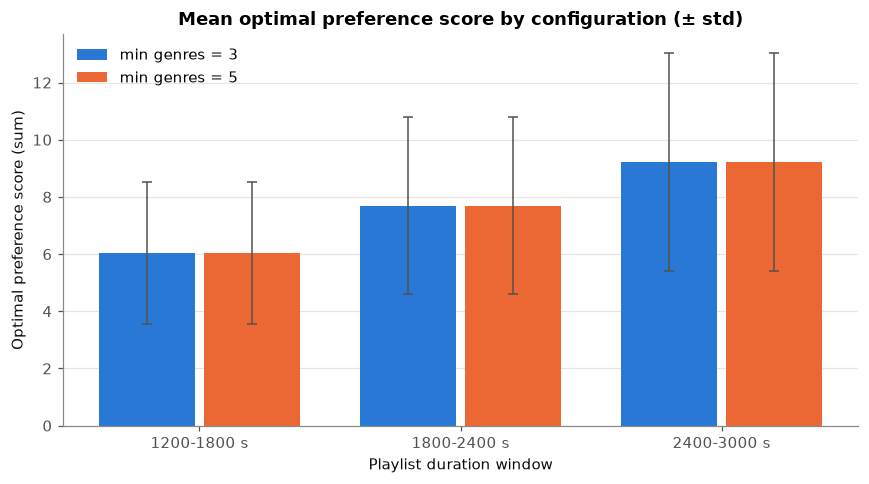

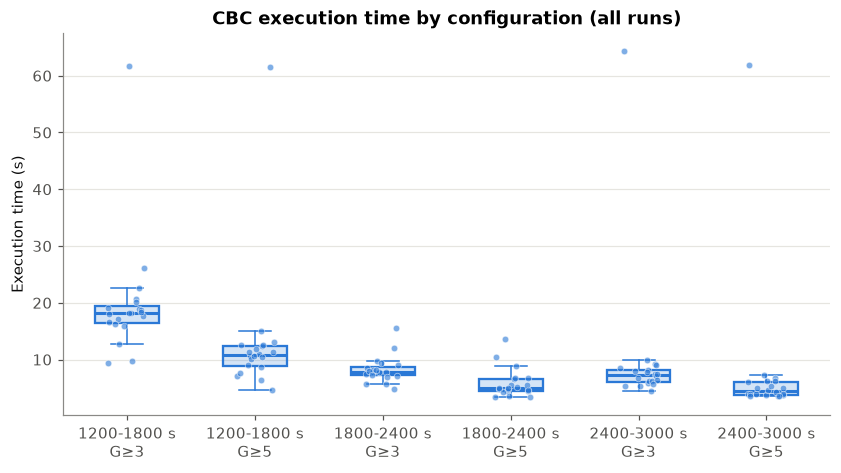

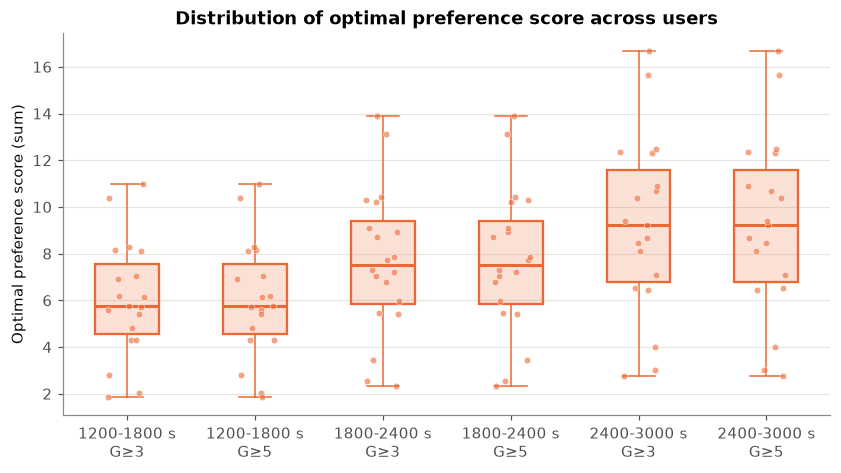

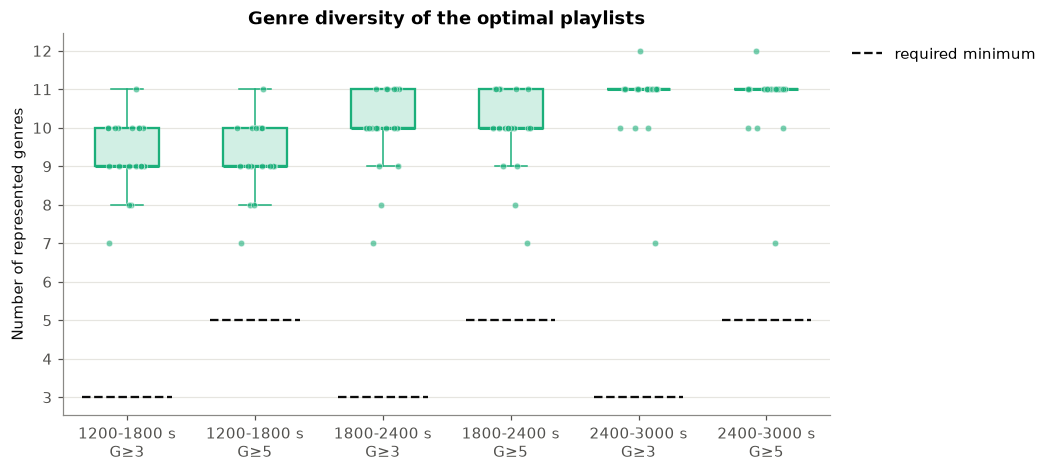

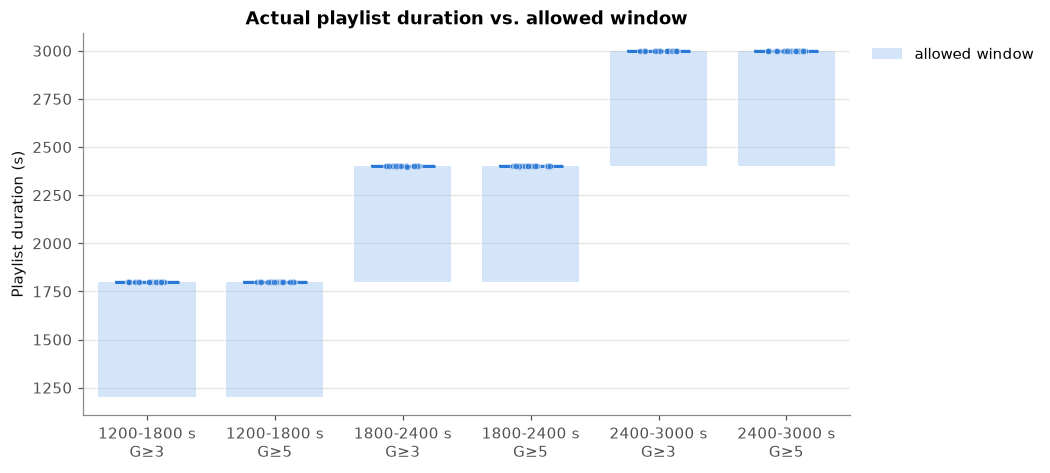

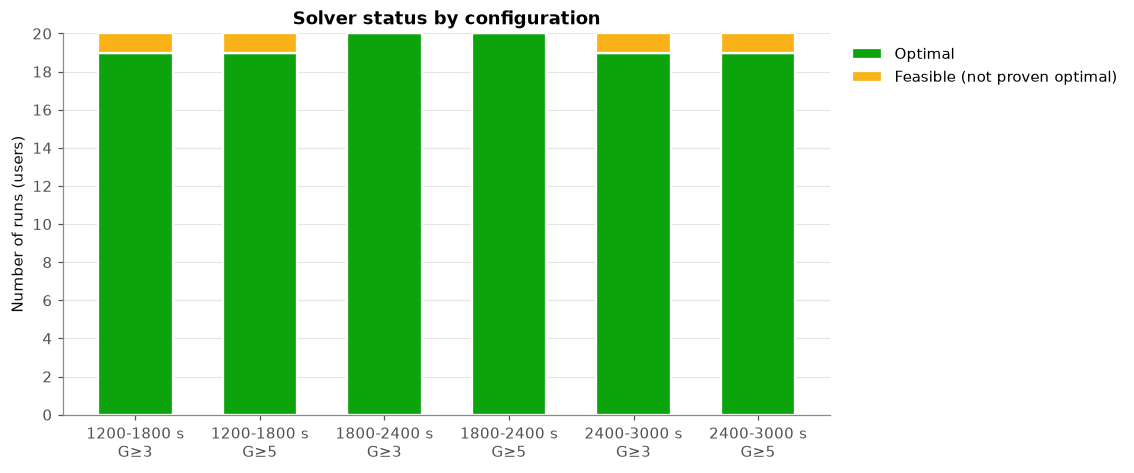

Saved statistics/tables to results and 6 figures to results\figures


,min_duration,max_duration,min_genres,n_runs,n_with_solution,n_successful,mean_preference,std_preference,min_preference,max_preference,mean_avg_pref_per_song,mean_n_songs,mean_duration,mean_genre_count,mean_execution_time,median_execution_time,max_execution_time,success_rate,duration_window
0,1200,1800,3,20,20,19,6.040237,2.487165,1.844929,10.983053,0.154997,38.526316,1799.736842,9.315789,19.815630,18.204485,61.662509,0.95,1200-1800
1,1200,1800,5,20,20,19,6.040237,2.487165,1.844929,10.983053,0.154997,38.526316,1799.736842,9.315789,12.886668,10.809651,61.474597,0.95,1200-1800
2,1800,2400,3,20,20,20,7.690184,3.096060,2.320128,13.911226,0.155966,48.750000,2399.900000,9.950000,8.247507,7.842555,15.590694,1.00,1800-2400
3,1800,2400,5,20,20,20,7.690184,3.096060,2.320128,13.911226,0.155966,48.750000,2399.900000,9.950000,5.874999,5.014680,13.570752,1.00,1800-2400
4,2400,3000,3,20,20,19,9.220084,3.820043,2.773611,16.685489,0.154159,59.105263,2999.894737,10.684211,9.960813,7.222672,64.386100,0.95,2400-3000
5,2400,3000,5,20,20,19,9.220087,3.820036,2.773677,16.685489,0.154159,59.105263,2999.894737,10.684211,7.627743,4.483231,61.815364,0.95,2400-3000


In [55]:
config_stats, status_summary, unsuccessful = compare(RESULTS_DIR / "experiment_summary.csv")
config_stats

In [56]:
status_summary

solver_status,min_duration,max_duration,min_genres,Feasible (not proven optimal),Optimal
0,1200,1800,3,1,19
1,1200,1800,5,1,19
2,1800,2400,3,0,20
3,1800,2400,5,0,20
4,2400,3000,3,1,19
5,2400,3000,5,1,19


In [57]:
# Runs that are not proven optimal (infeasible, time limit, ...). Their status is recorded, not treated as errors.
unsuccessful[["experiment_id", "user_id", "min_duration", "max_duration", "min_genres", "solver_status", "execution_time"]]

,experiment_id,user_id,min_duration,max_duration,min_genres,solver_status,execution_time
17,E1,2617701,1200,1800,3,Feasible (not proven optimal),61.662509
37,E2,2617701,1200,1800,5,Feasible (not proven optimal),61.474597
88,E5,182607714,2400,3000,3,Feasible (not proven optimal),64.386100
108,E6,182607714,2400,3000,5,Feasible (not proven optimal),61.815364
